# 10 — Walk-Forward Validation for Demand Forecasting

## Purpose

This notebook tests whether the V2 demand model works in a realistic forecasting scenario.

Instead of evaluating a fixed historical test set only, we simulate production:

```text
Past observations
      ↓
Train model
      ↓
Predict the next date
      ↓
That date's actual sales become known
      ↓
Move forward
      ↓
Predict again
```

### Why this matters

Our V2 model achieved approximately:

- Test MAE = **1.778**
- Test RMSE = **3.000**
- Test R² = **0.99923**

Those results are unusually strong, so we now want a stricter check.

### Important

This notebook uses **one-day-ahead forecasting**.

For each prediction date, every lag and rolling feature must be calculated using data from dates **before the prediction date**.

We will report:

- MAE
- RMSE
- R²
- WAPE
- Actual vs predicted demand
- Error distribution

We will NOT use `Inventory Level`, `Units Ordered`, or `Demand Forecast`.

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load the original data

In [2]:
df = pd.read_csv("../DATA/retail_store_inventory.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).reset_index(drop=True)

group_cols = ["Store ID", "Product ID"]

print("Shape:", df.shape)
print("Date:", df["Date"].min(), "→", df["Date"].max())

Shape: (73100, 15)
Date: 2022-01-01 00:00:00 → 2024-01-01 00:00:00


## 2. Leakage-safe feature function

This function creates features for a prediction date using only historical `Units Sold` values. The current date's target is never included in lag or rolling calculations.

In [3]:
def create_features(data):
    data = data.copy()

    data["Date"] = pd.to_datetime(data["Date"])
    data = data.sort_values(
        ["Store ID", "Product ID", "Date"]
    ).reset_index(drop=True)

    group_cols = ["Store ID", "Product ID"]
    demand_group = data.groupby(group_cols)["Units Sold"]

    # Calendar features
    data["Year"] = data["Date"].dt.year
    data["Month"] = data["Date"].dt.month
    data["Day"] = data["Date"].dt.day
    data["Day_of_Week"] = data["Date"].dt.dayofweek
    data["Week_of_Year"] = data["Date"].dt.isocalendar().week.astype(int)
    data["Quarter"] = data["Date"].dt.quarter
    data["Is_Weekend"] = (data["Day_of_Week"] >= 5).astype(int)

    # Historical demand
    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"Lag_{lag}"] = demand_group.shift(lag)

    # Leakage-safe rolling features
    data["Rolling_Mean_7"] = demand_group.transform(
        lambda x: x.shift(1).rolling(7).mean()
    )

    data["Rolling_Mean_14"] = demand_group.transform(
        lambda x: x.shift(1).rolling(14).mean()
    )

    data["Rolling_Mean_28"] = demand_group.transform(
        lambda x: x.shift(1).rolling(28).mean()
    )

    data["Rolling_Std_7"] = demand_group.transform(
        lambda x: x.shift(1).rolling(7).std()
    )

    data["Rolling_Std_28"] = demand_group.transform(
        lambda x: x.shift(1).rolling(28).std()
    )

    data["Rolling_Min_7"] = demand_group.transform(
        lambda x: x.shift(1).rolling(7).min()
    )

    data["Rolling_Max_7"] = demand_group.transform(
        lambda x: x.shift(1).rolling(7).max()
    )

    # Demand trend / momentum
    data["Demand_Momentum_7_28"] = (
        data["Rolling_Mean_7"] /
        data["Rolling_Mean_28"].replace(0, np.nan)
    )

    data["Demand_Trend_7_28"] = (
        data["Rolling_Mean_7"] -
        data["Rolling_Mean_28"]
    )

    data["Demand_CV_7"] = (
        data["Rolling_Std_7"] /
        data["Rolling_Mean_7"].replace(0, np.nan)
    )

    data["Demand_Change_1"] = (
        data.groupby(group_cols)["Units Sold"].diff(1)
    )

    # Price features
    data["Price_Difference"] = (
        data["Price"] - data["Competitor Pricing"]
    )

    data["Price_Ratio"] = (
        data["Price"] /
        data["Competitor Pricing"].replace(0, np.nan)
    )

    data["Relative_Price_Premium"] = (
        (data["Price"] - data["Competitor Pricing"]) /
        data["Competitor Pricing"].replace(0, np.nan)
    )

    data["Effective_Price"] = (
        data["Price"] * (1 - data["Discount"] / 100)
    )

    data["Promotion_Discount"] = (
        data["Holiday/Promotion"] * data["Discount"]
    )

    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    return data

df_features = create_features(df)

print("Feature creation complete.")
print("Shape:", df_features.shape)

Feature creation complete.
Shape: (73100, 45)


## 3. Define V2 features

In [4]:
categorical_features = [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

numerical_features = [
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Competitor Pricing",

    "Year",
    "Month",
    "Day",
    "Day_of_Week",
    "Week_of_Year",
    "Quarter",
    "Is_Weekend",

    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_7",
    "Lag_14",
    "Lag_21",
    "Lag_28",

    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_28",
    "Rolling_Std_7",
    "Rolling_Std_28",
    "Rolling_Min_7",
    "Rolling_Max_7",

    "Demand_Momentum_7_28",
    "Demand_Trend_7_28",
    "Demand_CV_7",
    "Demand_Change_1",

    "Price_Difference",
    "Price_Ratio",
    "Relative_Price_Premium",
    "Effective_Price",
    "Promotion_Discount"
]

feature_columns = categorical_features + numerical_features

excluded_columns = [
    "Inventory Level",
    "Units Ordered",
    "Demand Forecast"
]

for col in excluded_columns:
    assert col not in feature_columns

print("Total features:", len(feature_columns))
print("Excluded:", excluded_columns)

Total features: 40
Excluded: ['Inventory Level', 'Units Ordered', 'Demand Forecast']


## 4. Check the chronological dates

We reproduce the V2 evaluation periods so the walk-forward experiment starts from the same historical point.

In [5]:
unique_dates = np.sort(df_features["Date"].unique())

train_end_date = pd.Timestamp("2023-06-04")
walk_forward_start = pd.Timestamp("2023-06-05")
walk_forward_end = pd.Timestamp("2023-09-17")

print("Initial training ends:", train_end_date)
print("Walk-forward starts:", walk_forward_start)
print("Walk-forward ends:", walk_forward_end)

assert train_end_date < walk_forward_start
assert walk_forward_start <= walk_forward_end

Initial training ends: 2023-06-04 00:00:00
Walk-forward starts: 2023-06-05 00:00:00
Walk-forward ends: 2023-09-17 00:00:00


## 5. Verify that feature rows are available before forecasting

We remove rows without the required 28 days of history. The prediction date itself can remain in the dataframe because its features use `.shift(1)` for historical demand.

In [6]:
required_history = [
    "Lag_28",
    "Rolling_Mean_28",
    "Rolling_Std_28",
    "Rolling_Min_7",
    "Rolling_Max_7"
]

df_features = df_features.dropna(
    subset=required_history
).copy()

print("Rows after history requirement:", len(df_features))

Rows after history requirement: 70300


## 6. Walk-forward configuration

For computational practicality, we retrain the model periodically while making daily predictions. The default is every 7 prediction days.

Set `RETRAIN_EVERY = 1` for strict daily retraining, but that can be considerably slower.

In [7]:
RETRAIN_EVERY = 7

# Start with the Optuna parameters that produced the current benchmark.
best_params = {
    "iterations": 1800,
    "learning_rate": 0.0101618,
    "depth": 5,
    "l2_leaf_reg": 2.16498,
    "random_strength": 1.04311,
    "bagging_temperature": 1.49808
}

print("Retrain frequency:", RETRAIN_EVERY, "days")
print("Model parameters:", best_params)

Retrain frequency: 7 days
Model parameters: {'iterations': 1800, 'learning_rate': 0.0101618, 'depth': 5, 'l2_leaf_reg': 2.16498, 'random_strength': 1.04311, 'bagging_temperature': 1.49808}


## 7. Build a leakage-safe training/prediction helper

In [8]:
def prepare_xy(frame):
    X = frame[feature_columns].copy()
    y = frame["Units Sold"].copy()

    for col in categorical_features:
        X[col] = X[col].astype(str)

    return X, y

cat_feature_indices = [
    feature_columns.index(col)
    for col in categorical_features
]

print("Categorical feature indices:", cat_feature_indices)

Categorical feature indices: [0, 1, 2, 3, 4, 5]


## 8. Run walk-forward forecasting

At every forecast date:

1. Training data contains only dates before the forecast date.
2. The forecast row contains features generated from historical observations.
3. The model predicts that date.
4. The actual sales are retained only for evaluating the prediction and for creating features for later dates.

This is the key leakage test.

In [9]:
forecast_dates = pd.date_range(
    walk_forward_start,
    walk_forward_end,
    freq="D"
)

predictions = []
current_model = None

for step, forecast_date in enumerate(forecast_dates):

    # Only data strictly before the prediction date is used for training.
    train_data = df_features[
        df_features["Date"] < forecast_date
    ].copy()

    # Current day's rows are prediction rows.
    prediction_data = df_features[
        df_features["Date"] == forecast_date
    ].copy()

    # Make sure the prediction date has valid historical features.
    prediction_data = prediction_data.dropna(
        subset=feature_columns
    )

    if len(prediction_data) == 0:
        continue

    # Retrain periodically.
    if (
        current_model is None
        or step % RETRAIN_EVERY == 0
    ):
        X_train, y_train = prepare_xy(train_data)

        current_model = CatBoostRegressor(
            **best_params,
            loss_function="MAE",
            eval_metric="MAE",
            random_seed=42,
            verbose=False,
            allow_writing_files=False
        )

        current_model.fit(
            X_train,
            y_train,
            cat_features=cat_feature_indices,
            verbose=False
        )

    X_prediction, y_actual = prepare_xy(
        prediction_data
    )

    y_pred = current_model.predict(
        X_prediction
    )

    result = prediction_data[
        ["Date", "Store ID", "Product ID"]
    ].copy()

    result["Actual"] = y_actual.values
    result["Predicted"] = y_pred

    predictions.append(result)

    if (step + 1) % 10 == 0:
        print(
            f"Completed {step + 1}/{len(forecast_dates)} "
            f"forecast dates"
        )

walk_forward_results = pd.concat(
    predictions,
    ignore_index=True
)

print("\nWalk-forward predictions:", len(walk_forward_results))
print(
    "Dates:",
    walk_forward_results["Date"].min(),
    "→",
    walk_forward_results["Date"].max()
)

Completed 10/105 forecast dates
Completed 20/105 forecast dates
Completed 30/105 forecast dates
Completed 40/105 forecast dates
Completed 50/105 forecast dates
Completed 60/105 forecast dates
Completed 70/105 forecast dates
Completed 80/105 forecast dates
Completed 90/105 forecast dates
Completed 100/105 forecast dates

Walk-forward predictions: 10500
Dates: 2023-06-05 00:00:00 → 2023-09-17 00:00:00


## 9. Calculate walk-forward metrics

In [10]:
y_true = walk_forward_results["Actual"]
y_pred = walk_forward_results["Predicted"]

mae = mean_absolute_error(
    y_true,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

r2 = r2_score(
    y_true,
    y_pred
)

wape = (
    np.abs(y_true - y_pred).sum()
    / np.abs(y_true).sum()
) * 100

walk_forward_metrics = pd.DataFrame([{
    "Evaluation": "Walk-Forward",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
    "WAPE_%": wape
}])

walk_forward_metrics

,Evaluation,MAE,RMSE,R2,WAPE_%
0,Walk-Forward,1.826827,3.184989,0.999155,1.331935


## 10. Compare with the previous V2 benchmark

In [11]:
comparison = pd.DataFrame([
    {
        "Evaluation": "V2 fixed test benchmark",
        "MAE": 1.778,
        "RMSE": 3.000,
        "R2": 0.99923,
        "WAPE_%": np.nan
    },
    {
        "Evaluation": "Walk-Forward",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE_%": wape
    }
])

comparison

,Evaluation,MAE,RMSE,R2,WAPE_%
0,V2 fixed test benchmark,1.778000,3.000000,0.999230,NaN
1,Walk-Forward,1.826827,3.184989,0.999155,1.331935


## 11. Error analysis

In [12]:
walk_forward_results["Error"] = (
    walk_forward_results["Actual"] -
    walk_forward_results["Predicted"]
)

walk_forward_results["Absolute_Error"] = (
    walk_forward_results["Error"].abs()
)

walk_forward_results["APE"] = np.where(
    walk_forward_results["Actual"] != 0,
    walk_forward_results["Absolute_Error"]
    / walk_forward_results["Actual"] * 100,
    np.nan
)

print("Error statistics:")
print(
    walk_forward_results[
        ["Error", "Absolute_Error", "APE"]
    ].describe()
)

Error statistics:
              Error  Absolute_Error           APE
count  10500.000000    10500.000000  10434.000000
mean      -0.041734        1.826827      9.023228
std        3.184867        2.609119     54.864779
min      -43.306471        0.000092      0.000066
25%       -1.149917        0.513484      0.423890
50%        0.001646        1.139471      0.969528
75%        1.135875        2.218631      2.415146
max       65.473792       65.473792   2267.425810


## 12. Actual vs predicted demand

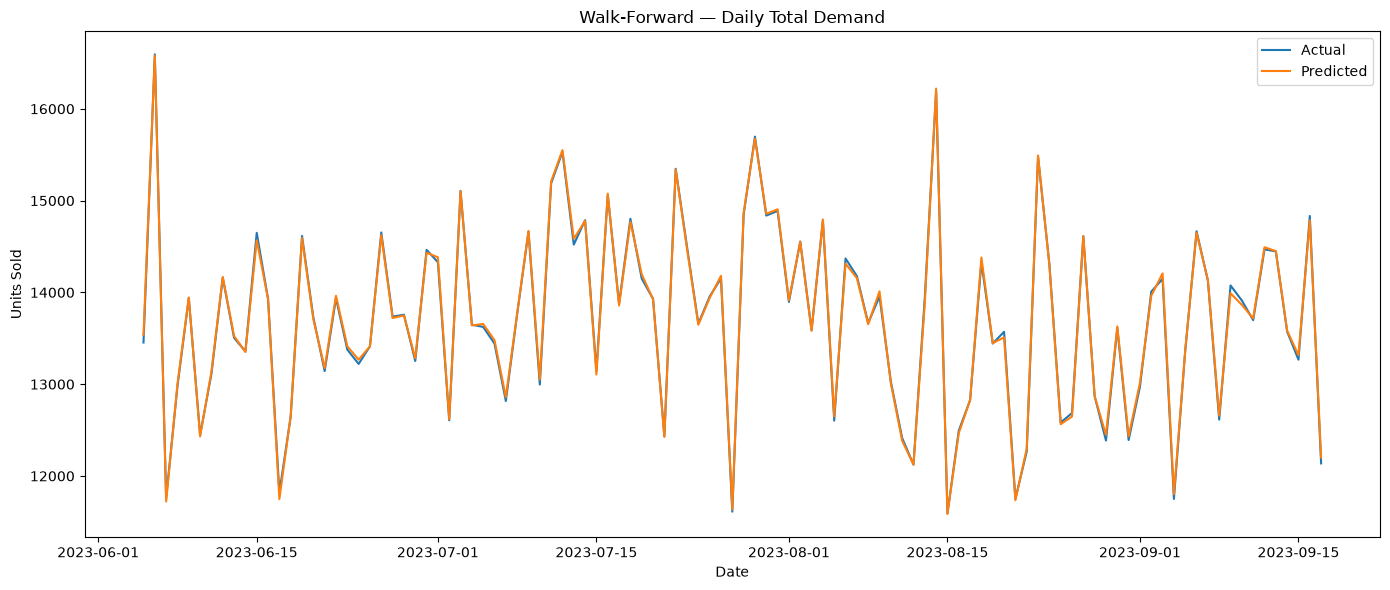

In [13]:
plot_sample = (
    walk_forward_results
    .groupby("Date")
    .agg(
        Actual=("Actual", "sum"),
        Predicted=("Predicted", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(14, 6))
plt.plot(
    plot_sample["Date"],
    plot_sample["Actual"],
    label="Actual"
)
plt.plot(
    plot_sample["Date"],
    plot_sample["Predicted"],
    label="Predicted"
)

plt.title("Walk-Forward — Daily Total Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Prediction error distribution

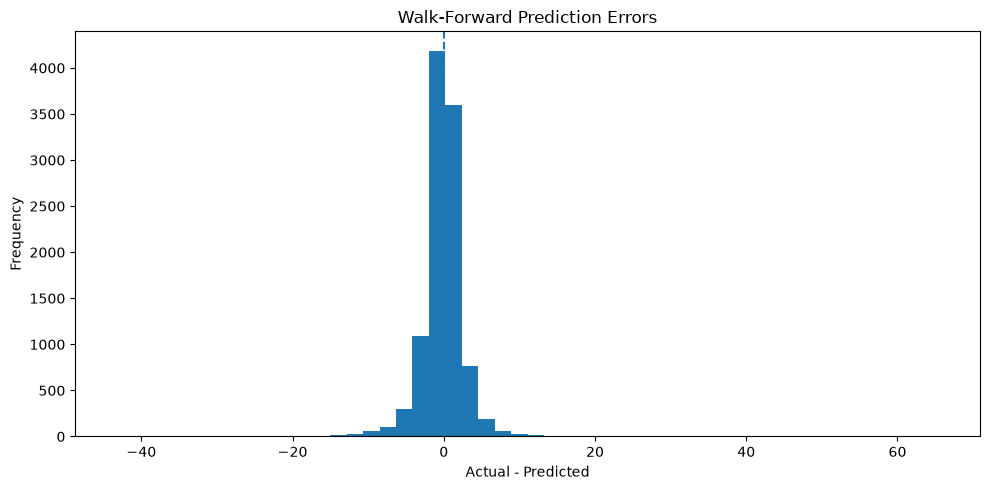

In [14]:
plt.figure(figsize=(10, 5))
plt.hist(
    walk_forward_results["Error"],
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title("Walk-Forward Prediction Errors")
plt.xlabel("Actual - Predicted")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 14. Worst prediction dates

In [15]:
daily_errors = (
    walk_forward_results
    .groupby("Date")
    .agg(
        Actual=("Actual", "sum"),
        Predicted=("Predicted", "sum"),
        Absolute_Error=("Absolute_Error", "sum")
    )
    .sort_values(
        "Absolute_Error",
        ascending=False
    )
)

daily_errors.head(20)

,Actual,Predicted,Absolute_Error
Date,,,
2023-08-13,13944,13885.449995,271.442870
2023-09-09,14076,13991.267264,261.841831
2023-07-13,14521,14583.178777,239.230989
2023-06-23,13377,13413.009141,237.661957
2023-08-10,13028,13010.542306,232.963208
2023-06-07,11758,11721.801196,224.639214
2023-09-07,14129,14134.781245,223.929059
2023-09-10,13912,13864.034723,221.714533
2023-07-23,14498,14474.592561,219.619204


## 15. Store-level walk-forward performance

In [16]:
store_results = (
    walk_forward_results
    .groupby("Store ID")
    .apply(
        lambda g: pd.Series({
            "MAE": mean_absolute_error(
                g["Actual"],
                g["Predicted"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    g["Actual"],
                    g["Predicted"]
                )
            ),
            "R2": r2_score(
                g["Actual"],
                g["Predicted"]
            )
        }),
        include_groups=False
    )
    .sort_values("MAE")
)

store_results

,MAE,RMSE,R2
Store ID,,,
S004,1.785389,2.938335,0.999234
S001,1.789101,2.953964,0.999280
S005,1.794849,3.075266,0.999237
S002,1.825573,3.061950,0.999223
S003,1.939225,3.811594,0.998801


## 16. Save the walk-forward results

In [24]:
from pathlib import Path
output_dir = Path("../models")
output_dir.mkdir(parents=True, exist_ok=True)

walk_forward_results.to_csv(
    output_dir / "walk_forward_predictions.csv",
    index=False
)

walk_forward_metrics.to_csv(
    output_dir / "walk_forward_metrics.csv",
    index=False
)

print("Saved:")
print(output_dir / "walk_forward_predictions.csv")
print(output_dir / "walk_forward_metrics.csv")

Saved:
..\models\walk_forward_predictions.csv
..\models\walk_forward_metrics.csv


# Interpretation guide

Compare the walk-forward MAE against the V2 fixed-test MAE of approximately **1.778**.

### Scenario A — Walk-forward MAE remains very low
Example:

```text
Fixed test:   1.78
Walk-forward: 2–5
```

This would strongly support the V2 feature engineering.

### Scenario B — Moderate degradation
Example:

```text
Fixed test:   1.78
Walk-forward: 10–30
```

The model still has useful forecasting power, but the fixed-test result was optimistic.

### Scenario C — Large degradation
Example:

```text
Fixed test:   1.78
Walk-forward: 50+
```

This would indicate that the original evaluation was not representative of production forecasting.

### Important

Do not change the model based on the walk-forward result until we inspect it.

Send the following outputs after running:

1. `walk_forward_metrics`
2. `comparison`
3. `store_results`
4. `daily_errors.head(20)`

Then we can determine whether the V2 model is genuinely strong and what to improve next.